### Retaining only "TRANSFER" and "CASH_OUT" columns

In [5]:
import pandas as pd 
data = pd.read_csv("../data/transaction_data.csv")
data = data[data["type"].isin(["TRANSFER", "CASH_OUT"])]

In [10]:
data.shape

(2770409, 11)

In [16]:
fraud_rate_per_transaction = data.groupby("type")["isFraud"].mean()
fraud_rate = data["isFraud"].mean()

print(f'fraud rate across dataset: {fraud_rate:.3%}')
print('fraud rates in TRANSFER and CASH_OUT transactions:')
print(fraud_rate_per_transaction)


fraud rate across dataset: 0.296%
fraud rates in TRANSFER and CASH_OUT transactions:
type
CASH_OUT    0.001840
TRANSFER    0.007688
Name: isFraud, dtype: float64


### Train test split

In [34]:
from sklearn.model_selection import train_test_split

X = data[["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig", 
          "oldbalanceDest", "newbalanceDest"]]

Y = data["isFraud"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, stratify=Y, random_state=42
)

print(f'Shape of X_train:   {X_train.shape}')
print(f'Shape of X_test:    {X_test.shape}')

Y_train_fraud = Y_train.mean()
Y_test_fraud = Y_test.mean()

print(f'y_train fraud rate: {Y_train_fraud:.3%}')
print(f'y_test_fraud rate:  {Y_test_fraud:.3%}')

Shape of X_train:   (2216327, 7)
Shape of X_test:    (554082, 7)
y_train fraud rate: 0.296%
y_test_fraud rate:  0.297%


### Dummy classifier

In [ ]:
# dummy classifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, Y_train)
y_pred_dummy = dummy.predict(X_test)

print(f"Accuracy:  {accuracy_score(Y_test, y_pred_dummy):.3%}")
print(f"Recall:    {recall_score(Y_test, y_pred_dummy):.3f}")
print(f"Precision: {precision_score(Y_test, y_pred_dummy, zero_division=0):.3f}")

Accuracy:  99.703%
Recall:    0.000
Precision: 0.000


### Logistic regresssion baseline

In [39]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

numeric_cols = ["step", "amount", "oldbalanceOrg", "newbalanceOrig",
                "oldbalanceDest", "newbalanceDest"]
categorical_cols = ["type"]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(), categorical_cols),
])

log_reg = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

log_reg.fit(X_train, Y_train)
y_pred_lr = log_reg.predict(X_test)


print(f"Accuracy:  {accuracy_score(Y_test, y_pred_lr):.3%}")
print(f"Recall:    {recall_score(Y_test, y_pred_lr):.3f}")
print(f"Precision: {precision_score(Y_test, y_pred_lr, zero_division=0):.3f}")

Accuracy:  94.134%
Recall:    0.884
Precision: 0.043


- Recall 0.884: it catches 88% of fraud. The test set has about 1,640 frauds, so it catches about 1,450 and misses about 190. The dummy caught 0.

- Precision 0.043: only 4.3% of flagged transactions are really fraud. That’s about 23 genuine customers blocked for every fraud caught, roughly 34,000 flags in total. In production that would be unworkable.

- Accuracy 94.1% is lower than the dummy’s 99.7%, yet this model is far more useful. That’s the accuracy trap again, and a strong line for your README.

**Why precision is so low?**
class_weight="balanced" makes the model very eager to flag fraud.
The default threshold of 0.5 isn’t tuned to the bank’s costs. Choosing a better one is M2.
Logistic regression can only draw a straight-line boundary between fraud and genuine. XGBoost in M3 can learn more complex patterns.

**Why stratify?**
Fraud is only 0.3% of rows. A random split could leave the test set with more or less fraud than reality, making scores unreliable. Stratifying keeps the fraud rate equal in train and test (0.296% vs 0.297%), so the test set represents real data.

**Why does a pipeline prevent leakage?**
Preprocessing learns from data. The scaler learns each column's mean and standard deviation. In a pipeline, these are learned from the training set only and then applied unchanged to the test set. Scaling the full dataset first would let test information influence training, giving over-optimistic scores.

**What does a baseline prove?**
It sets the bar a model must beat to show it has learned real signal. The dummy (always "not fraud") scores 99.7% accuracy but 0 recall, showing that accuracy is misleading. Logistic regression reaches 0.884 recall (precision 0.043), so the features carry real fraud signal. It is now the benchmark XGBoost must beat.

### Confusion matrix to See exactly which errors the model makes

In [42]:
from sklearn.metrics import confusion_matrix, f1_score

cm = confusion_matrix(Y_test, y_pred_lr)
print(cm)
print(f"F1: {f1_score(Y_test, y_pred_lr):.3f}")

[[520127  32312]
 [   190   1453]]
F1: 0.082


In [43]:
from sklearn.metrics import roc_auc_score, average_precision_score

y_proba_lr = log_reg.predict_proba(X_test)[:, 1]

print(f"ROC AUC: {roc_auc_score(Y_test, y_proba_lr):.3f}")
print(f"PR AUC:  {average_precision_score(Y_test, y_proba_lr):.3f}")

ROC AUC: 0.976
PR AUC:  0.588


In [46]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_validate(
    log_reg, X_train, Y_train,
    cv=cv,
    scoring=["roc_auc", "average_precision"],
    n_jobs=-1,
)

for metric in ["test_roc_auc", "test_average_precision"]:
    print(f"{metric}: mean {scores[metric].mean():.3f}, std {scores[metric].std():.3f}")

test_roc_auc: mean 0.976, std 0.002
test_average_precision: mean 0.592, std 0.011


### Choosing a threshold:

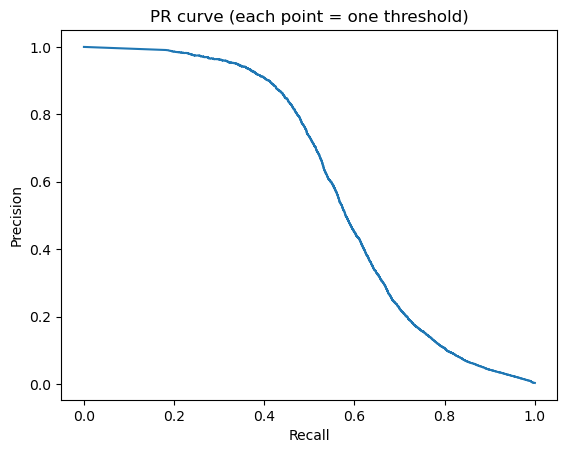

Best threshold: 0.83, cost: £1,077,480


In [47]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve
import numpy as np
import matplotlib.pyplot as plt

# 1. Out-of-fold fraud probabilities for the training set
proba_oof = cross_val_predict(log_reg, X_train, Y_train, cv=cv,
                              method="predict_proba", n_jobs=-1)[:, 1]

# 2. PR curve: one point per threshold
precision, recall, thresholds = precision_recall_curve(Y_train, proba_oof)
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR curve (each point = one threshold)")
plt.show()

# 3. Cost at each threshold
cost_fn, cost_fp = 500, 10
grid = np.linspace(0.01, 0.99, 99)
costs = []
for t in grid:
    pred = (proba_oof >= t).astype(int)
    fn = ((pred == 0) & (Y_train == 1)).sum()
    fp = ((pred == 1) & (Y_train == 0)).sum()
    costs.append(fn * cost_fn + fp * cost_fp)

best_t = grid[np.argmin(costs)]
print(f"Best threshold: {best_t:.2f}, cost: £{min(costs):,}")

### Applying Optimal threshold to test ad visualising optimal threshold on PR curve

In [48]:
y_pred_tuned = (y_proba_lr >= best_t).astype(int)

print(confusion_matrix(Y_test, y_pred_tuned))
print(f"Recall:    {recall_score(Y_test, y_pred_tuned):.3f}")
print(f"Precision: {precision_score(Y_test, y_pred_tuned):.3f}")
print(f"F1:        {f1_score(Y_test, y_pred_tuned):.3f}")

[[544318   8121]
 [   397   1246]]
Recall:    0.758
Precision: 0.133
F1:        0.226


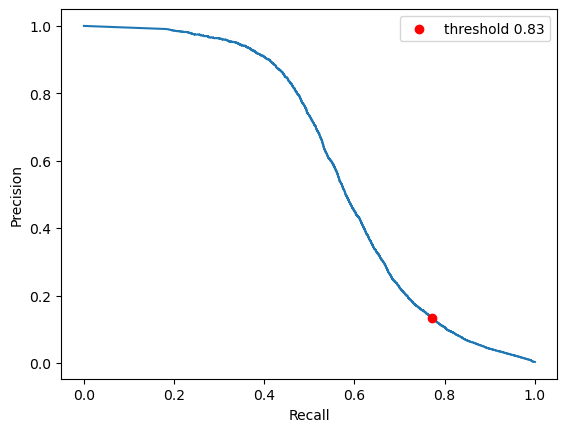

In [49]:
idx = np.argmin(np.abs(thresholds - best_t))
plt.plot(recall, precision)
plt.scatter(recall[idx], precision[idx], color="red", zorder=3, label=f"threshold {best_t:.2f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

## Final Validation and metrics

### 1. Confusion matrix at threshold 0.5
| | Predicted genuine | Predicted fraud |
| --- | --- | --- |
| Actually genuine | 520,127 | 32,312 |
| Actually fraud | 190 | 1,453 |

*What do the 190 and the 32,312 mean for the bank? (one or two sentences)*
- 190 means the bank missed 190 transactions that were actually fruadulent wrongly flagged 32,312 transaction as fraudulent when they were actualy genuine

### 2. Precision, recall and F1
Recall 0.884 · Precision 0.043 · F1 0.082

*Use your "shots" analogy: why is recall high but precision low? What does a low F1 tell you?*
- recall is high because the model the model more biased/swayed to predicting a transaction as fraudulent, meaning it takes more shots, and as a result is more likely to flag a greter proportion of the actually fradulent transaction due to this higher volume. Precision is low because, the shots being taken are not being made with high certainty. So, when a transaction is being flagged as fraud, there a relatively high chance it actually is not fraud. a low f1 tells me that the model is lacking in either its precision or recall is lacking. 

### 3. ROC AUC vs PR AUC
ROC AUC 0.976 · PR AUC 0.588 · Random PR AUC ≈ 0.003 (the fraud rate)

*Answer M2 question 1:*
- *What each curve plots (axes)*
    PR plots precision vs Recall while ROC plots recall vs false positive rate
- *Why ROC looks better: what false positives are divided by in each*
    ROC looks better because false positives are divided by number of transactions, a large number, which dwarfs number of false positives. PR curve is divided by a smaller number - total number of fraudulent transactions. Same number of false positives in both but the dividing and nature ROC makes it seem like the model makes less mistakes than it actually does. the PR shows true nature of false positives. 4.3% PR says 95% of actual fraud is missed. 5.8% ROC says “of genuine transactions, 94.2% were correctly not flagged.”
- *Which one you trust here, and why*
    trust PR when fraud is rare 

### 4. Cross-validation (5-fold StratifiedKFold, training set)
ROC AUC 0.976 ± 0.002 · PR AUC 0.592 ± 0.011

*Why run cross-validation, and what do the small ± values tell you?*
    - A single train/test split could be lucky or unlucky. Cross-validation trains and scores the model 5 times on different folds of the training set (each with the same fraud rate), giving a more reliable estimate.
    - The means match the single-split scores (0.976 and 0.588), and the small ± values mean scores barely change between folds, so the model's performance is stable, not luck.


### 5. Threshold choice
Costs (illustrative): missed fraud £500, blocked customer £10. Best threshold from out-of-fold training probabilities: 0.83 [PR curve with red dot]
*Answer M2 question 2:*
- *How 0.83 was found (the cost loop, on out-of-fold training data)*
    `cross_val_predict` gave each training row a fraud probability from a model that hadn't trained on it. I tried 99 thresholds (0.01–0.99), counted FN and FP at each, calculated cost = FN × £500 + FP × £10, and picked the cheapest: 0.83.
- *Why not 0.5*
    0.5 assumes both errors cost the same. They don't, and `class_weight="balanced"` also inflates the probabilities, so 0.5 flags far too many genuine customers.
- *Why not choose it on the test set*
    choosing the threshold on the test set makes it part of training, so it stops being unseen data and the final score would be over-optimistic. The test set was used once, only to check the chosen threshold.

### 6. Test-set result at 0.83
| Threshold | FN | FP | Recall | Precision | F1 | Cost |
| --- | --- | --- | --- | --- | --- | --- |
| 0.50 | 190 | 32,312 | 0.884 | 0.043 | 0.082 | £418,120 |
| 0.83 | 397 | 8,121 | 0.758 | 0.133 | 0.226 | £279,710 |

*What you gained, what you gave up, and the cost saving (~33%).*
    - **Gained:** 24,191 fewer genuine customers blocked (32,312 → 8,121). Precision tripled (0.043 → 0.133) and F1 almost tripled (0.082 → 0.226).
    - **Gave up:** 207 more frauds missed (190 → 397). Recall fell from 0.884 to 0.758.
    - **Net:** expected cost fell from £418,120 to £279,710, about 33% lower, with the same model. Only the threshold changed.
    - The test result matches the out-of-fold estimate (recall ~0.77, precision ~0.13), so the threshold generalises.

### 7. Limitations
- The costs are illustrative; real costs would give a different threshold.
- Precision is still low: 87% of flags are genuine customers. Logistic regression can only draw a straight-line boundary; a non-linear model (XGBoost) should separate fraud better.
- PaySim is synthetic, so real-world performance would differ.


**Unifying summary**
    • Higher threshold: fewer shots, so fewer wrong shots (fewer FP). But more transactions get passed as genuine, and more real frauds slip through among them (more FN).
    • Lower threshold: more shots, so more wrong shots (more FP). But fewer transactions get passed, so fewer frauds slip through (fewer FN).